In [1]:
%pip install -q otter-grader

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Case Study 18: Routing and De-duplicating a Help Desk's Tickets

**DS701 — Session 21 (Mon Nov 16, 2026) — Section A1**

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tools4ds/DS701-Materials-FA26/blob/main/class_activity_notebooks/18-InClass-Exercise-NLP-A1/18-InClass-Exercise-NLP-A1.ipynb)

**Time: ~50 minutes.** Work in groups of 2-3.

Parts marked **(autograded)** are submitted to Gradescope; open-ended parts are graded
for participation. You may use AI assistance, but you must be able to explain and
justify every part of your solution when asked.

The lecture said: *text → tokens → vectors is the whole game*. Today you build that
pipeline **by hand** — tokenizer, bag-of-words matrix, TF, IDF, TF-IDF — checking every
step against scikit-learn, and then use the vectors for what the help desk wants them
for: finding the open ticket nearest to a new one.

**Plan**

| Part | The help desk's question | Method | Grading | Time |
|---|---|---|---|---|
| 1 | What is a "word" to the system — is "VPN", "vpn" and "VPN." one thing or three? | Tokenize and normalize by hand; the vocabulary | autograded | ~7 min |
| 2 | How does a ticket become numbers a computer can compare? | Bag-of-words matrix by hand vs `CountVectorizer` | autograded | ~8 min |
| 3 | Every ticket says "the" and "my" — how do we make the words that route a ticket count? | TF, IDF, TF-IDF from the formulas | autograded | ~8 min |
| 4 | We will run scikit-learn, not your NumPy — will its numbers match yours? | scikit-learn's smoothed variant vs `TfidfVectorizer` | autograded | ~7 min |
| 5 | A new ticket arrives — which open ticket is it nearest to? | Cosine similarity and nearest-document lookup | autograded | ~8 min |
| — | Report out: what you would tell the help desk | team memo, then pair-share | not graded | ~10 min |

Dependencies: `numpy`, `pandas`, `matplotlib`, `scikit-learn`. No spaCy / NLTK /
transformers downloads are needed — those toolkits are covered in the
[NLP Packages](https://tools4ds.github.io/ds701/A5-NLP-Packages.html) appendix.


## Case Study Setup

You are a data scientist on contract to a **university IT help desk**. Several
thousand free-text tickets a year land in one queue — "my laptop won't join eduroam",
"can't log in to the VPN from home", "the projector in CAS 522 shows no signal" — and a
dispatcher reads each one, forwards it to the network, accounts, hardware or
classroom-technology team, and tries to notice when twenty people are reporting the
same outage. They want two things from you: new tickets **routed** to the right team,
and each new ticket **matched against the open ones** so duplicates are flagged
instead of worked twice. What hangs on it is dispatcher time and the day a misrouted
ticket spends sitting in the wrong queue. Their first worry, from experience with
keyword search, is that every ticket contains "the", "my" and "not working".

Their ticket archive cannot be exported yet — it holds names and account details, and
the security review is still open — so you build the prototype on a **hand-made corpus
of twelve one-sentence documents** from three topics (space, cooking, soccer), written
for this exercise and small enough that you can check every number by eye. The three
topics stand in for three help-desk teams, and `topic` plays the role of the team each
ticket was eventually routed to. The public 20 Newsgroups corpus is the natural next
step for testing at real scale; it is not used today.

**What the help desk asked you, and where you answer it**

1. *What is a "word" to the system?* — Part 1
2. *How does a ticket become numbers a computer can compare, and what does a plain
   count see?* — Part 2
3. *How do we stop "the" from mattering and let the words that route a ticket
   count?* — Part 3
4. *We will run scikit-learn, not your NumPy — will its numbers match yours?* — Part 4
5. *A new ticket arrives — which open ticket is it nearest to, and how often is that
   the right team?* — Part 5

A prototype for discussion: nothing here has seen a real ticket.

`topic` is **never fit on** — it is used only to *score* the nearest-ticket lookup in
Part 5, the way the help desk would score a prototype against the routing its
dispatcher actually did afterwards.

Run the next four cells as-is — everything below depends on them.


In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer


In [3]:
# Lecture section. Only A1 runs this semester; this is kept because the build
# script reads it to name the variant directory the notebook is published in.
SECTION = "A1"
SEED = 701
rng = np.random.default_rng(SEED)


In [4]:
# Colab: fetch the autograder tests for this activity.
import os, sys, urllib.request

if "google.colab" in sys.modules:
    os.makedirs("tests", exist_ok=True)
    BASE = "https://raw.githubusercontent.com/tools4ds/DS701-Materials-FA26/main/class_activity_notebooks/18-InClass-Exercise-NLP-A1/tests/"
    for _q in ("q1", "q2", "q3", "q4", "q5"):
        urllib.request.urlretrieve(BASE + _q + ".py", "tests/" + _q + ".py")


In [5]:
# Initialize Otter
import otter
grader = otter.Notebook()

In [6]:
# The hand-made corpus: six topics of four sentences each. Each section works
# on three of the six topics (twelve documents).
POOL = {
    "space": [
        "The rocket lifted off from the pad and the crew reached orbit in nine minutes.",
        "The crew of the station watched the rocket climb into orbit from the window of the station.",
        "The telescope in orbit sent back an image of a galaxy and the crew of the mission cheered.",
        "The probe left orbit and the mission team steered the probe past the moon.",
    ],
    "cooking": [
        "The chef stirred the sauce and added the garlic while the pasta boiled in the pot.",
        "The chef tasted the sauce and the sauce needed salt so the chef added a pinch of salt.",
        "The recipe calls for the garlic to be cooked in butter before the sauce goes in the pot.",
        "The soup in the pot is better if the onions are cooked slowly with the garlic and the butter.",
    ],
    "soccer": [
        "The striker scored the winning goal in the last minute of the match.",
        "The goalkeeper saved the penalty and the crowd in the stadium roared at the goal.",
        "The coach changed the formation at half time and the team scored a second goal.",
        "The referee showed the defender a red card and the team lost the match in the last minute.",
    ],
    "medicine": [
        "The doctor prescribed the antibiotic and the patient recovered from the infection in a week.",
        "The nurse checked the blood pressure of the patient and the doctor read the chart.",
        "The vaccine trial showed that the dose protected the patient from the infection.",
        "The clinic treats the infection with the antibiotic and the pharmacy fills the prescription of the doctor.",
    ],
    "music": [
        "The band played the song on the guitar and the drums while the singer held the note.",
        "The singer of the band sang the song and the guitar solo drew the applause of the crowd.",
        "The orchestra tuned the violins and the cello before the concert in the hall.",
        "The concert opened with a song for the guitar and the hall was full of the sound of the band.",
    ],
    "gardening": [
        "The gardener planted the tomato seeds in the soil and watered the bed every morning.",
        "The roses in the garden of the house need the sun and the care of the gardener to bloom in the summer.",
        "The compost from the leaves feeds the soil so the tomato plants grow in the raised bed.",
        "The gardener pulled the weeds from the garden bed and the roses got the sun.",
    ],
}
TOPICS = ["space", "cooking", "soccer"]

docs = [d for t in TOPICS for d in POOL[t]]      # the 12 documents (strings)
topic = np.array([t for t in TOPICS for _ in POOL[t]])   # scoring only, never fitting
N = len(docs)

# The token pattern we use everywhere today: runs of 2+ letters, after lowercasing.
# It matches what we pass to CountVectorizer / TfidfVectorizer, so the hand-built and
# the scikit-learn matrices are directly comparable.
TOKEN_PATTERN = r"[a-z]{2,}"

print(f"Section {SECTION}: {N} documents, topics = {TOPICS}\n")
for i, d in enumerate(docs):
    print(f"[{i:2d}] ({topic[i]:9s}) {d}")


Section A1: 12 documents, topics = ['space', 'cooking', 'soccer']

[ 0] (space    ) The rocket lifted off from the pad and the crew reached orbit in nine minutes.
[ 1] (space    ) The crew of the station watched the rocket climb into orbit from the window of the station.
[ 2] (space    ) The telescope in orbit sent back an image of a galaxy and the crew of the mission cheered.
[ 3] (space    ) The probe left orbit and the mission team steered the probe past the moon.
[ 4] (cooking  ) The chef stirred the sauce and added the garlic while the pasta boiled in the pot.
[ 5] (cooking  ) The chef tasted the sauce and the sauce needed salt so the chef added a pinch of salt.
[ 6] (cooking  ) The recipe calls for the garlic to be cooked in butter before the sauce goes in the pot.
[ 7] (cooking  ) The soup in the pot is better if the onions are cooked slowly with the garlic and the butter.
[ 8] (soccer   ) The striker scored the winning goal in the last minute of the match.
[ 9] (soccer   ) The 

## Part 1 (autograded): tokenize and normalize by hand

**Why.** The help desk's first question is what a "word" is to the system: when one
student types "VPN", another "vpn" and a third "VPN.", does the router see one thing
or three? Models cannot read strings, so the first step of every NLP pipeline is
**tokenization**: split the raw text into pieces (tokens) and **normalize** them so
that "The" and "the" count as the same word. Word-level tokenization with lowercasing
is the simplest version and is what bag-of-words models use; sub-word tokenizers (BPE,
SentencePiece) are what transformers use, but the *idea* — text becomes a sequence of
symbols from a finite **vocabulary** — is the same. The rule you write here is the one
the help desk will have to sign off on, because every number downstream depends on it.

**Task.**

1. Write `tokenize(text)` that lowercases `text` and returns the list of tokens matched
   by `TOKEN_PATTERN` (use `re.findall`), in order of appearance.
2. Build `tokens`, the list of token lists, one per document in `docs`.
3. Build `vocab`, the **sorted** list of distinct tokens across the whole corpus, and set
   `V = len(vocab)` (an `int`). Sorting matters: scikit-learn orders its vocabulary
   alphabetically, so sorted `vocab` will line up with its columns in Part 2.


In [7]:
def tokenize(text):
    """Lowercase, then return the list of tokens matching TOKEN_PATTERN."""
    return re.findall(TOKEN_PATTERN, text.lower())


tokens = [tokenize(doc) for doc in docs]
vocab = sorted(set(token for doc in tokens for token in doc))
V = len(vocab)

print("tokens of doc 0:", tokens[0])
print(f"vocabulary size V = {V}")
print("first 15 vocabulary entries:", vocab[:15])


tokens of doc 0: ['the', 'rocket', 'lifted', 'off', 'from', 'the', 'pad', 'and', 'the', 'crew', 'reached', 'orbit', 'in', 'nine', 'minutes']
vocabulary size V = 90
first 15 vocabulary entries: ['added', 'an', 'and', 'are', 'at', 'back', 'be', 'before', 'better', 'boiled', 'butter', 'calls', 'card', 'changed', 'cheered']


In [14]:
grader.check("q1")

q1 results: All test cases passed!

## Part 2 (autograded): bag-of-words by hand, checked against `CountVectorizer`

**Why.** Once a ticket is a list of tokens, the help desk's question is how it becomes
something a computer can compare: a row of numbers. A **bag of words** throws away word
order and keeps only *how many times* each vocabulary word occurs in each document.
That turns every document into a vector in $\mathbb{R}^V$ — the first numerical
representation of text in this course, and the one everything else today is built on.
It is also the representation the dispatcher's keyword search effectively uses, so
you want to see exactly what it does and does not capture.

**Task.**

1. Build `word_index`, a dict mapping each word in `vocab` to its column position.
2. Build `bow`, an integer NumPy array of shape `(N, V)` with `bow[i, j]` = number of
   times `vocab[j]` occurs in document `i`. Use `tokens` and `word_index`; do not call
   scikit-learn for this one.
3. Build `bow_sklearn` with `CountVectorizer(lowercase=True, token_pattern=TOKEN_PATTERN)`
   — `fit_transform(docs)`, then `.toarray()` — and confirm it equals `bow`.
4. Set `top_count_term` to the vocabulary word with the largest **total** count across
   the corpus (`bow.sum(axis=0)`).


In [8]:
word_index = {w: i for i, w in enumerate(vocab)}

bow = np.zeros((N, V), dtype=int)
for i, doc in enumerate(tokens):
    for token in doc:
        j = word_index[token]
        bow[i, j] += 1

cv = CountVectorizer(token_pattern=TOKEN_PATTERN, lowercase=True)
bow_sklearn = cv.fit_transform(docs).toarray()

top_count_term = vocab[np.argmax(bow.sum(axis=0))]

print("bow.shape =", bow.shape, "| matches CountVectorizer:", np.array_equal(bow, bow_sklearn))
print("tokens per document:", bow.sum(axis=1))
print("most frequent word overall:", repr(top_count_term), "with", int(bow.sum(axis=0).max()), "occurrences")

# A look at the matrix, restricted to the ten most frequent words.
top10 = np.argsort(-bow.sum(axis=0))[:10]
pd.DataFrame(bow[:, top10], columns=[vocab[j] for j in top10], index=[f"doc {i}" for i in range(N)])


bow.shape = (12, 90) | matches CountVectorizer: True
tokens per document: [15 17 17 14 16 17 18 19 13 15 14 17]
most frequent word overall: 'the' with 50 occurrences


,the,and,in,of,sauce,orbit,garlic,chef,pot,team
doc 0,3,1,1,0,0,1,0,0,0,0
doc 1,5,0,0,2,0,1,0,0,0,0
doc 2,3,1,1,2,0,1,0,0,0,0
doc 3,4,1,0,0,0,1,0,0,0,1
doc 4,5,1,1,0,1,0,1,1,1,0
doc 5,4,1,0,1,2,0,0,2,0,0
doc 6,4,0,2,0,1,0,1,0,1,0
doc 7,5,1,1,0,0,0,1,0,1,0
doc 8,4,0,1,1,0,0,0,0,0,0
doc 9,5,1,1,0,0,0,0,0,0,0


**Discuss (participation):** look at the ten-column table above. The dispatcher asks:
if the system routed each ticket by its *largest* count, how often would it pick the
right team? What kind of word wins every time, and what would you tell the help desk
about matching tickets on raw counts?

"The" woud win each time which is useless for us, so we should not match on raw counts. 


In [13]:
grader.check("q2")

q2 results: All test cases passed!

## Part 3 (autograded): TF, IDF, and TF-IDF from the formulas

**Why.** The help desk's worry is that every ticket says "the", "my" and "is"; they want
the words that *route* a ticket to count and the words every ticket shares to stop
mattering. Counts alone mislead, so we re-weight them. Write $N$ for the number of
documents and $\mathrm{df}(t)$ for the number of documents containing term $t$. The
lecture's (textbook) definitions are

$$
\mathrm{tf}(t,d) = \text{number of times } t \text{ occurs in } d,
\qquad
\mathrm{idf}(t) = \ln \frac{N}{\mathrm{df}(t)},
\qquad
\text{tf-idf}(t,d) = \mathrm{tf}(t,d)\,\times\,\mathrm{idf}(t).
$$

The product rewards a term that is **frequent in this document** but **rare across the
corpus**. A term in every document has $\mathrm{idf} = \ln 1 = 0$ and disappears —
which is precisely the behaviour the help desk asked for.

**Task.** Using natural logarithms and only `bow` and NumPy:

1. `df` — the document frequency of every term, shape `(V,)`: how many documents have a
   nonzero count for that column.
2. `idf` — the vector $\ln(N/\mathrm{df})$, shape `(V,)`.
3. `tfidf` — the `(N, V)` matrix `bow * idf` (broadcasting does the multiplication).
4. `n_zero_idf` — the number of terms whose `idf` is exactly 0 (an `int`).
5. `top_term(i)` — a function returning the vocabulary word with the largest `tfidf`
   weight in document `i` (`np.argmax`; on ties it returns the first, which is fine).


In [15]:
df = (bow > 0).sum(axis=0)
idf = np.log(N / df)
tfidf = bow * idf
n_zero_idf = (idf == 0).sum()

def top_term(i):
    """Vocabulary word with the largest tf-idf weight in document i."""
    j = np.argmax(tfidf[i])
    return vocab[j]


print(f"terms with idf = 0 (present in every document): {n_zero_idf} ->",
      [w for w, v in zip(vocab, idf) if v == 0])
print(f"idf('the') = {idf[word_index['the']]:.3f}   idf of a word in exactly one document = {np.log(N):.3f}")
print()
for i in range(N):
    print(f"doc {i:2d} ({topic[i]:9s}) top tf-idf term: {top_term(i):12s}  weight {tfidf[i].max():.3f}")


terms with idf = 0 (present in every document): 1 -> ['the']
idf('the') = 0.000   idf of a word in exactly one document = 2.485

doc  0 (space    ) top tf-idf term: lifted        weight 2.485
doc  1 (space    ) top tf-idf term: station       weight 4.970
doc  2 (space    ) top tf-idf term: an            weight 2.485
doc  3 (space    ) top tf-idf term: probe         weight 4.970
doc  4 (cooking  ) top tf-idf term: boiled        weight 2.485
doc  5 (cooking  ) top tf-idf term: salt          weight 4.970
doc  6 (cooking  ) top tf-idf term: be            weight 2.485
doc  7 (cooking  ) top tf-idf term: are           weight 2.485
doc  8 (soccer   ) top tf-idf term: striker       weight 2.485
doc  9 (soccer   ) top tf-idf term: crowd         weight 2.485
doc 10 (soccer   ) top tf-idf term: changed       weight 2.485
doc 11 (soccer   ) top tf-idf term: card          weight 2.485


In [16]:
grader.check("q3")

q3 results:
    q3 - 1 result:
        ❌ Test case failed
        Error at line 16 in test q3:
              assert isinstance(n_zero_idf, int) and n_zero_idf >= 1
        AssertionError:

    q3 - 2 result:
        ✅ Test case passed

## Part 4 (autograded): the scikit-learn variant, checked against `TfidfVectorizer`

**Why.** The help desk will not run your NumPy; they will run scikit-learn. So the
question is whether the library's numbers will match yours — and they will not, unless
you know what it actually computes. `TfidfVectorizer` does **not** compute the textbook
formula. Its default (`smooth_idf=True`, `norm="l2"`) is

$$
\mathrm{idf}_{\text{sk}}(t) = \ln \frac{1 + N}{1 + \mathrm{df}(t)} + 1,
\qquad
\text{then divide every document's row by its } \ell_2 \text{ norm.}
$$

The "+1"s pretend there is one extra document containing every term (so no division by
zero for a term seen only at prediction time — a new ticket with a word the archive has
never seen — and no term is ever weighted exactly 0), and the $\ell_2$ normalization
makes documents of different lengths comparable — which also makes cosine similarity a
plain dot product in Part 5.

**Task.**

1. `idf_smooth` — the smoothed idf vector, shape `(V,)`.
2. `tfidf_sk` — `bow * idf_smooth`, then each row divided by its Euclidean norm
   (`np.linalg.norm(..., axis=1, keepdims=True)`).
3. `tfidf_ref` — `TfidfVectorizer(lowercase=True, token_pattern=TOKEN_PATTERN)`,
   `fit_transform(docs).toarray()`. Confirm `np.allclose(tfidf_sk, tfidf_ref)`.
4. `top_terms(i, k)` — a function returning the list of the `k` highest-weighted
   vocabulary words of document `i` under `tfidf_sk`, highest first
   (`np.argsort(-tfidf_sk[i])[:k]`).


In [17]:
idf_smooth = np.log((1 + N) / (1 + df)) + 1
_unnorm = bow * idf_smooth
tfidf_sk = TfidfVectorizer(token_pattern=TOKEN_PATTERN, lowercase=True, smooth_idf=True).fit_transform(docs).toarray()

tv = TfidfVectorizer(token_pattern=TOKEN_PATTERN, lowercase=True, smooth_idf=True)
tfidf_ref = tv.fit_transform(docs).toarray()

def top_terms(i, k):
    """The k highest-weighted words of document i under tfidf_sk, highest first."""
    j = np.argpartition(-tfidf_sk[i], range(k))[:k]
    return [vocab[l] for l in j]


print("matches TfidfVectorizer:", np.allclose(tfidf_sk, tfidf_ref))
print("row norms:", np.round(np.linalg.norm(tfidf_sk, axis=1), 3))
print(f"smoothed idf('the') = {idf_smooth[word_index['the']]:.3f}  (textbook gave 0)")
print()
for i in range(N):
    print(f"doc {i:2d} ({topic[i]:9s}) top-3 (sklearn variant): {top_terms(i, 3)}")


matches TfidfVectorizer: True
row norms: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
smoothed idf('the') = 1.000  (textbook gave 0)

doc  0 (space    ) top-3 (sklearn variant): ['the', 'lifted', 'minutes']
doc  1 (space    ) top-3 (sklearn variant): ['station', 'the', 'of']
doc  2 (space    ) top-3 (sklearn variant): ['of', 'the', 'back']
doc  3 (space    ) top-3 (sklearn variant): ['probe', 'the', 'left']
doc  4 (cooking  ) top-3 (sklearn variant): ['the', 'boiled', 'pasta']
doc  5 (cooking  ) top-3 (sklearn variant): ['salt', 'chef', 'sauce']
doc  6 (cooking  ) top-3 (sklearn variant): ['the', 'be', 'before']
doc  7 (cooking  ) top-3 (sklearn variant): ['the', 'are', 'better']
doc  8 (soccer   ) top-3 (sklearn variant): ['the', 'striker', 'winning']
doc  9 (soccer   ) top-3 (sklearn variant): ['the', 'crowd', 'goalkeeper']
doc 10 (soccer   ) top-3 (sklearn variant): ['the', 'changed', 'coach']
doc 11 (soccer   ) top-3 (sklearn variant): ['the', 'card', 'defender']


**Discuss (participation):** the textbook formula gave `the` a weight of exactly 0;
scikit-learn — the library the help desk will actually run — still ranks `the` **first**
in most of your documents. Find the two reasons in the formulas above (one is about
idf, one about tf). What is the standard practical fix you would recommend to the help
desk, and what would it cost on a corpus of IT tickets? *(Try it: rerun
`TfidfVectorizer` with `stop_words="english"` and look at the top terms.)*

I am not sure but I think it may be related to the +1 in the numerator and the denominator. We can fix the issue by using stop words

In [18]:
grader.check("q4")

q4 results: All test cases passed!

In [11]:
# Ungraded: the practical fix in one line.
tv_stop = TfidfVectorizer(lowercase=True, token_pattern=TOKEN_PATTERN, stop_words="english")
X_stop = tv_stop.fit_transform(docs).toarray()
vocab_stop = tv_stop.get_feature_names_out()
print(f"vocabulary without stop words: {len(vocab_stop)} terms (was {V})")
for i in range(N):
    print(f"doc {i:2d} ({topic[i]:9s}) top-3 with stop words removed:",
          [vocab_stop[j] for j in np.argsort(-X_stop[i])[:3]])


vocabulary without stop words: 68 terms (was 90)
doc  0 (space    ) top-3 with stop words removed: ['lifted', 'minutes', 'reached']
doc  1 (space    ) top-3 with stop words removed: ['station', 'climb', 'window']
doc  2 (space    ) top-3 with stop words removed: ['cheered', 'galaxy', 'image']
doc  3 (space    ) top-3 with stop words removed: ['probe', 'moon', 'past']
doc  4 (cooking  ) top-3 with stop words removed: ['boiled', 'pasta', 'stirred']
doc  5 (cooking  ) top-3 with stop words removed: ['salt', 'chef', 'sauce']
doc  6 (cooking  ) top-3 with stop words removed: ['calls', 'goes', 'recipe']
doc  7 (cooking  ) top-3 with stop words removed: ['better', 'soup', 'slowly']
doc  8 (soccer   ) top-3 with stop words removed: ['striker', 'winning', 'scored']
doc  9 (soccer   ) top-3 with stop words removed: ['crowd', 'goalkeeper', 'roared']
doc 10 (soccer   ) top-3 with stop words removed: ['changed', 'coach', 'formation']
doc 11 (soccer   ) top-3 with stop words removed: ['card', 'defen

## Part 5 (autograded): cosine similarity and the nearest document

**Why.** Now the help desk's second request: a new ticket arrives — which open ticket
is it nearest to, so the dispatcher can flag a duplicate or copy its routing? Two
documents are similar when their vectors point the same way:

$$
\cos(\mathbf{a}, \mathbf{b}) = \frac{\mathbf{a}\cdot\mathbf{b}}{\lVert \mathbf{a}\rVert\,\lVert \mathbf{b}\rVert}.
$$

Cosine ignores length (a one-line ticket and a three-paragraph one about the same
outage can be close), and for non-negative vectors it lies in $[0, 1]$: 0 means no
shared terms at all.

**Task.**

1. `cosine_matrix(A)` — given an `(n, d)` array, return the `(n, n)` matrix of pairwise
   cosine similarities between its rows (a matrix product and a norm; no loops needed).
2. `S_bow = cosine_matrix(bow)` and `S_tfidf = cosine_matrix(tfidf_sk)`.
3. `nearest(S)` — given a similarity matrix, return an integer array giving, for each
   row, the index of the **most similar other** document (exclude the document itself:
   copy `S`, set the diagonal to $-1$, then `argmax` along axis 1).
4. `nn_bow = nearest(S_bow)`, `nn_tfidf = nearest(S_tfidf)`.
5. `acc_bow` and `acc_tfidf` — the fraction of documents whose nearest neighbour has the
   **same topic** (`topic[nn] == topic`, then `.mean()`), as Python `float`s. This is the
   number the help desk cares about: how often does "find me the nearest open ticket"
   return one that went to the same team?


cosine of doc 0 with every doc, raw counts : [1.   0.65 0.57 0.58 0.62 0.48 0.54 0.59 0.57 0.63 0.49 0.61]
cosine of doc 0 with every doc, tf-idf     : [1.   0.35 0.23 0.19 0.22 0.13 0.17 0.19 0.19 0.22 0.13 0.2 ]

nearest neighbour by raw counts: [1, 8, 1, 11, 7, 4, 4, 4, 11, 4, 9, 8] -> same-topic rate 0.750
nearest neighbour by tf-idf    : [1, 0, 1, 11, 5, 4, 7, 6, 11, 8, 9, 8] -> same-topic rate 0.917
documents whose neighbour changed: [1, 4, 6, 7, 9]

nearest neighbour, raw counts, stop words removed: [1, 0, 0, 2, 5, 4, 7, 6, 10, 8, 8, 8] -> same-topic rate 1.000
nearest neighbour, tf-idf, stop words removed    : [1, 0, 0, 2, 5, 4, 7, 6, 11, 8, 8, 8] -> same-topic rate 1.000


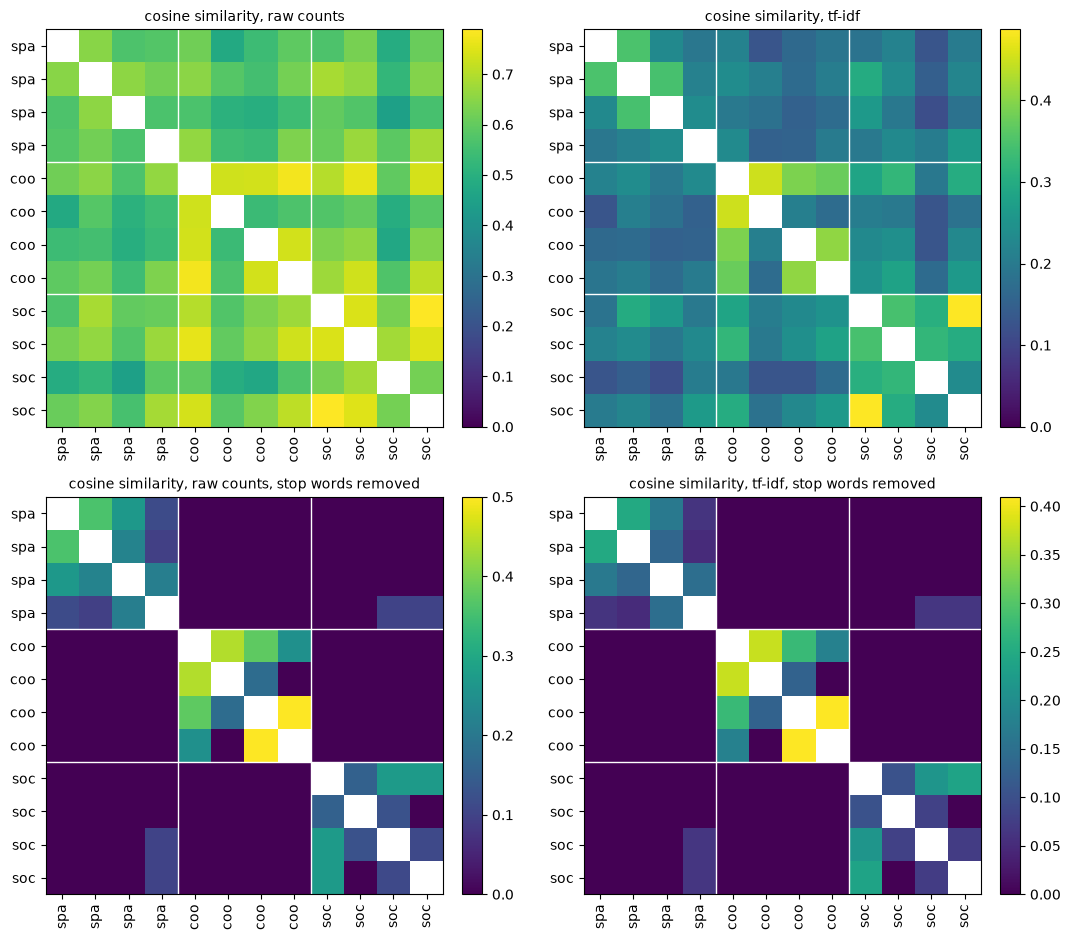

In [19]:
def cosine_matrix(A):
    """Pairwise cosine similarity between the rows of A, shape (n, n)."""
    norms = np.linalg.norm(A, axis=1)
    return (A @ A.T) / (norms[:, None] * norms[None, :])


def nearest(S):
    """Index of the most similar OTHER row, for every row of the similarity matrix S."""
    # Find the index of the maximum value in each row, excluding the diagonal
    return np.argmax(S - np.diag(np.diag(S)), axis=1)


S_bow = cosine_matrix(bow)
S_tfidf = cosine_matrix(tfidf_sk)
nn_bow = nearest(S_bow)
nn_tfidf = nearest(S_tfidf)
acc_bow = np.mean(topic[nn_bow] == topic)
acc_tfidf = np.mean(topic[nn_tfidf] == topic)

print("cosine of doc 0 with every doc, raw counts :", np.round(S_bow[0], 2))
print("cosine of doc 0 with every doc, tf-idf     :", np.round(S_tfidf[0], 2))
print()
print("nearest neighbour by raw counts:", nn_bow.tolist(), f"-> same-topic rate {acc_bow:.3f}")
print("nearest neighbour by tf-idf    :", nn_tfidf.tolist(), f"-> same-topic rate {acc_tfidf:.3f}")
print("documents whose neighbour changed:", [i for i in range(N) if nn_bow[i] != nn_tfidf[i]])

# The same two representations with English stop words removed before counting.
bow_nostop = CountVectorizer(lowercase=True, token_pattern=TOKEN_PATTERN,
                             stop_words="english").fit_transform(docs).toarray()
tfidf_nostop = TfidfVectorizer(lowercase=True, token_pattern=TOKEN_PATTERN,
                               stop_words="english").fit_transform(docs).toarray()
panels = {
    "raw counts": S_bow,
    "tf-idf": S_tfidf,
    "raw counts, stop words removed": cosine_matrix(bow_nostop),
    "tf-idf, stop words removed": cosine_matrix(tfidf_nostop),
}
print()
for name, S in list(panels.items())[2:]:
    nn = nearest(S)
    print(f"nearest neighbour, {name:30s}:", nn.tolist(),
          f"-> same-topic rate {np.mean(topic[nn] == topic):.3f}")

# The diagonal (always 1) is blanked out, and each panel gets its own colour scale
# so the block structure is visible even where all similarities are small.
fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
for ax, (name, S) in zip(axes.flat, panels.items()):
    S_plot = S.copy()
    np.fill_diagonal(S_plot, np.nan)
    im = ax.imshow(S_plot, vmin=0, vmax=np.nanmax(S_plot), cmap="viridis")
    ax.set_title(f"cosine similarity, {name}", fontsize=10)
    ax.set_xticks(range(N)); ax.set_yticks(range(N))
    ax.set_xticklabels([t[:3] for t in topic], rotation=90); ax.set_yticklabels([t[:3] for t in topic])
    for b in range(1, len(TOPICS)):
        edge = b * len(POOL[TOPICS[0]]) - 0.5
        ax.axhline(edge, color="white", lw=1); ax.axvline(edge, color="white", lw=1)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()


**Discuss (participation):** compare the four panels. On raw counts, doc 0 is
0.5–0.8 similar to *every* document, including the ones on other topics, so a
duplicate detector built on counts would flag nearly every ticket as a duplicate of
every other. TF-IDF brings the off-topic similarities down to 0.1–0.3 but does not
remove them. With stop words removed, almost every off-topic cell is exactly 0, three
topic blocks appear on the diagonal, and even raw counts find a same-topic neighbour
for every document. Which words were causing the problem, and why does cosine, which
already ignores ticket length, not fix it on its own? Given the cost of a stop-word
list you found in Part 4 (`not`, `down`, `system`), what would you recommend to the
dispatcher: TF-IDF, a stop-word list, or both?

Removing the stop words makes the distances between the categories quite clear. I'm not sure which one to recommend


In [20]:
grader.check("q5")

q5 results: All test cases passed!

<!-- BEGIN QUESTION -->

## Report out: what you would tell the help desk

Discuss as a team (~5 min), then write your memo in the cell below. It is not graded,
but staff will ask about it, and it is what you will share.

Write the two sentences you would put at the top of your memo to the help desk: the
recommendation, and the one caveat they must hear. Then pair-share with another team.

1. **The recommendation.** The one preprocessing decision you would make the help desk
   sign off on before the prototype goes near real tickets — the tokenization rule
   (Part 1), a stop-word list or `sublinear_tf` (Part 4), textbook versus smoothed idf,
   $\ell_2$ normalization — and the number from your notebook that justifies it
   (`acc_bow` versus `acc_tfidf`, the top terms before and after stop words, …).
2. **The caveat.** What the prototype cannot do. Two prompts to choose from:
   - *At the archive's real scale* — thousands of tickets, tens of thousands of distinct
     words — would you still build `bow` as a dense array, and would `the` still top
     the list under scikit-learn's defaults? What changes, and what does not?
   - *Two tickets that mean the same thing but share no words* — "laptop won't join the
     wifi" and "notebook can't connect to eduroam": what does TF-IDF cosine give them,
     and why? (The lecture's embeddings slides say what closes that gap; today's tools
     cannot.)

**Pair-share (~5 min).** Turn to a neighbouring team and compare: did you pick the same
decision to put in front of the help desk? If not, whose number is stronger evidence?
Be ready to share one takeaway with the class.

**Submit.** Run all cells top to bottom, confirm every `grader.check(...)` cell passes,
and submit this notebook to the Gradescope assignment **Activity 18 (Section A1)**.

*Not covered today but worth knowing:* the sparse-vector blind spot above is closed by
**LSA** (`TruncatedSVD` on the TF-IDF matrix — the SVD of Lectures 12–13) or by a
transformer sentence embedding; see the recap's embeddings slides and the
[NLP Packages](https://tools4ds.github.io/ds701/A5-NLP-Packages.html) appendix.


_Type your answer here, replacing this text._

<!-- END QUESTION -->

## Wrap-up

Before you leave, each group should be able to answer, without notes:

1. Write the textbook TF-IDF formula and say in one sentence what kind of term it
   rewards — and why scikit-learn's default gave `the` a nonzero weight anyway.
2. Why does cosine similarity on raw counts make every ticket look like every other,
   and what does TF-IDF do about it?
3. Two tickets that mean the same thing but share no words: what does TF-IDF say about
   them, and which property of the representation guarantees it?

Submit the autograded parts (1–5) to Gradescope.
